# Вероятности исходов матчей

[Отчёт](../reports/report.md) · [PDF](../reports/report.pdf)

## Подготовка

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
from match_forecast.__main__ import run

_ = run(ROOT, train=False)
REPORTS = ROOT / 'reports'
FIGURES = REPORTS / 'figures'
predictions = pd.read_csv(REPORTS / 'final_predictions.csv')
metrics = pd.read_csv(REPORTS / 'tables/final_model_metrics.csv')
configuration = json.loads((ROOT / 'config/report_model.json').read_text(encoding='utf-8'))
display(pd.Series(configuration))

kind                            match
model            dense_32_16_ensemble
training                    expanding
probabilities                     raw
evaluation              retrospective
profile                   regularized
dtype: object

## Лиги и обучение

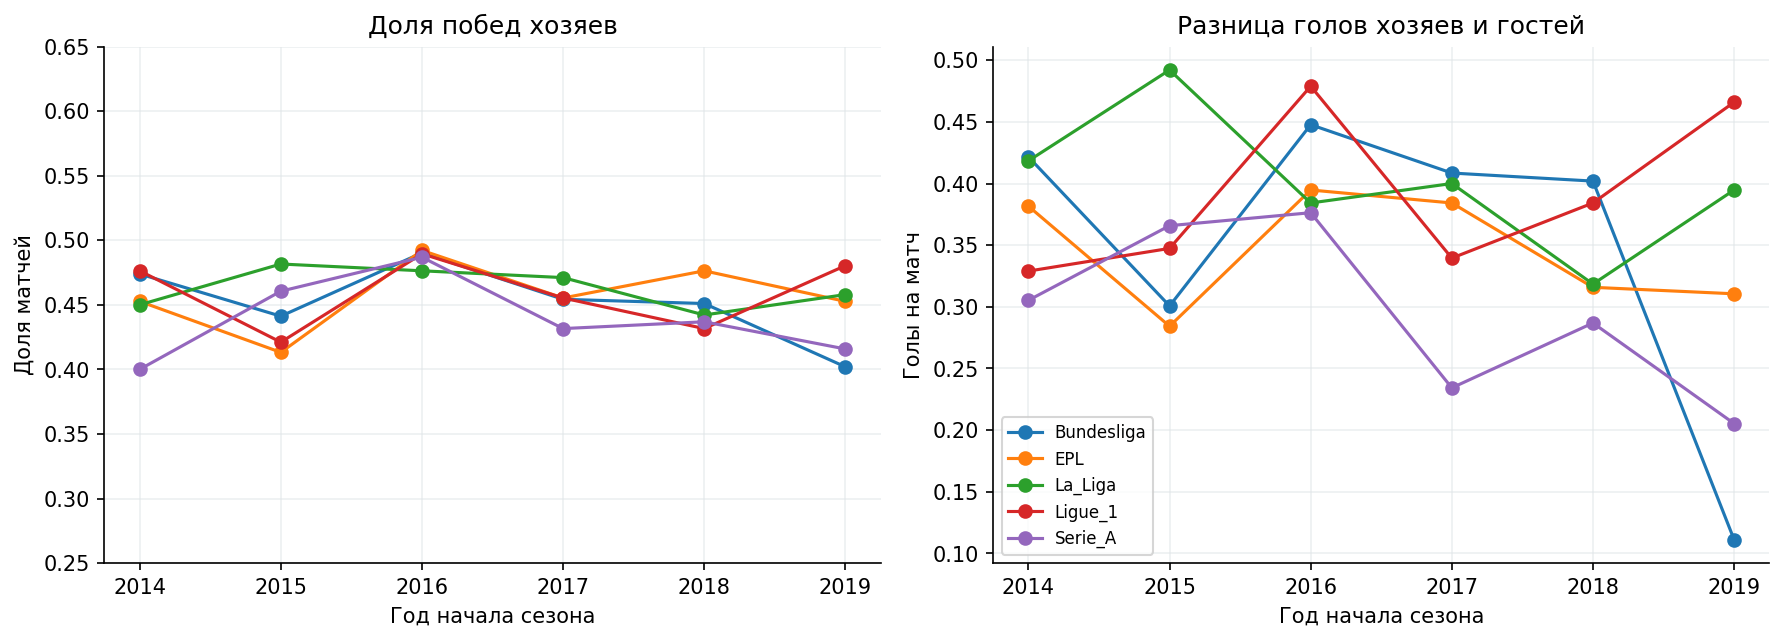

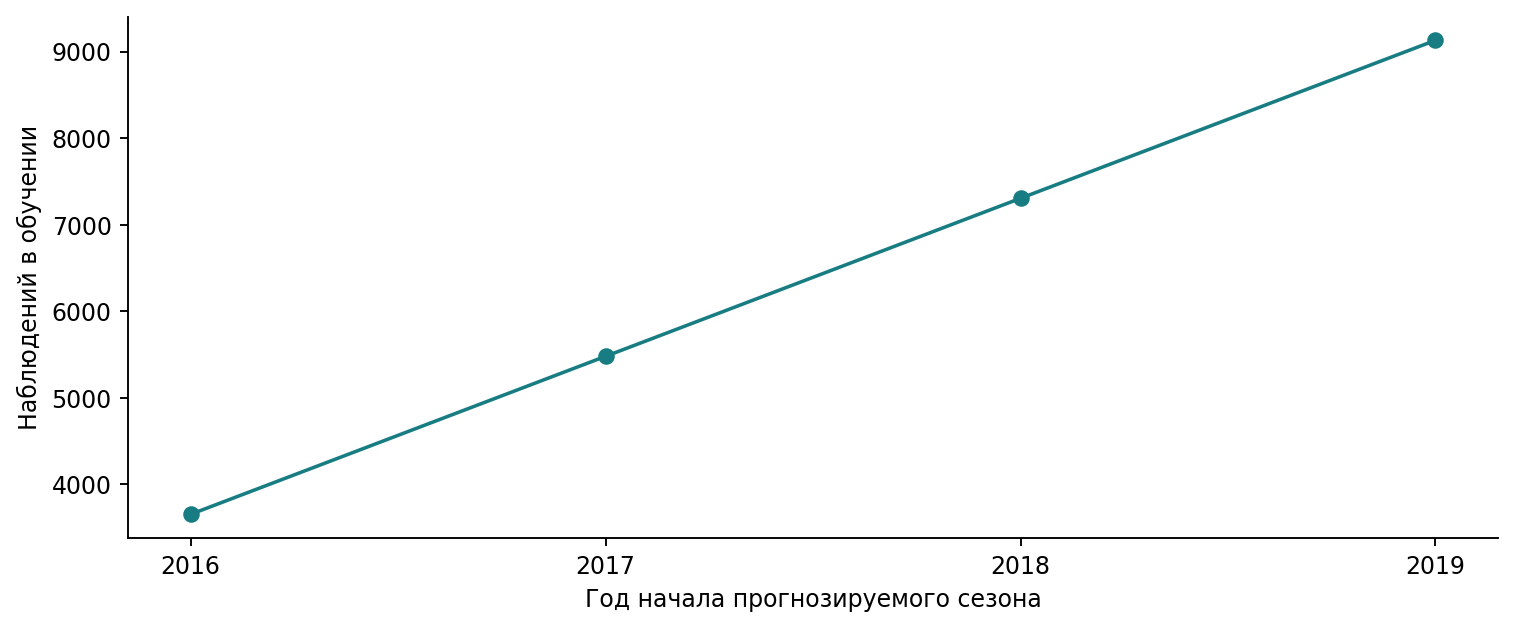

In [2]:
display(Image(filename=str(FIGURES / 'home_advantage.png'), width=1000))
display(Image(filename=str(FIGURES / 'final_training_window.png'), width=950))

## Качество вероятностей

n           1725.000000
log_loss       0.991866
brier          0.591309
accuracy       0.514203
dtype: float64

,model,group,n,log_loss,brier,accuracy
0,constant,all,1725,1.070456,0.647669,0.441159
8,elo,all,1725,1.004276,0.600039,0.517101
16,poisson,all,1725,1.025790,0.615207,0.489855
24,neural,all,1725,0.991866,0.591309,0.514203


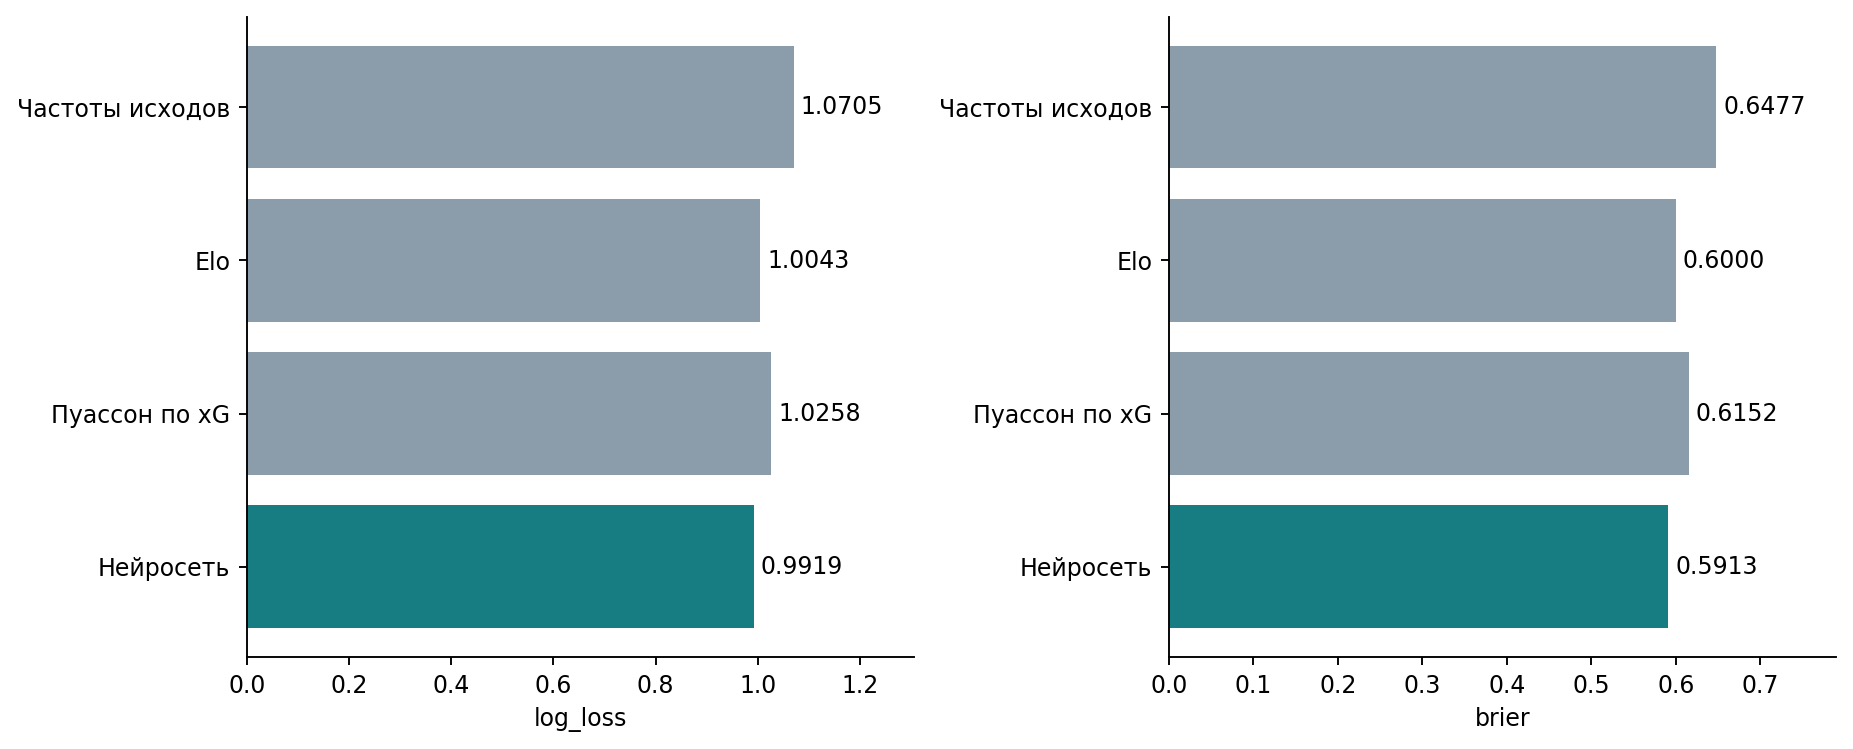

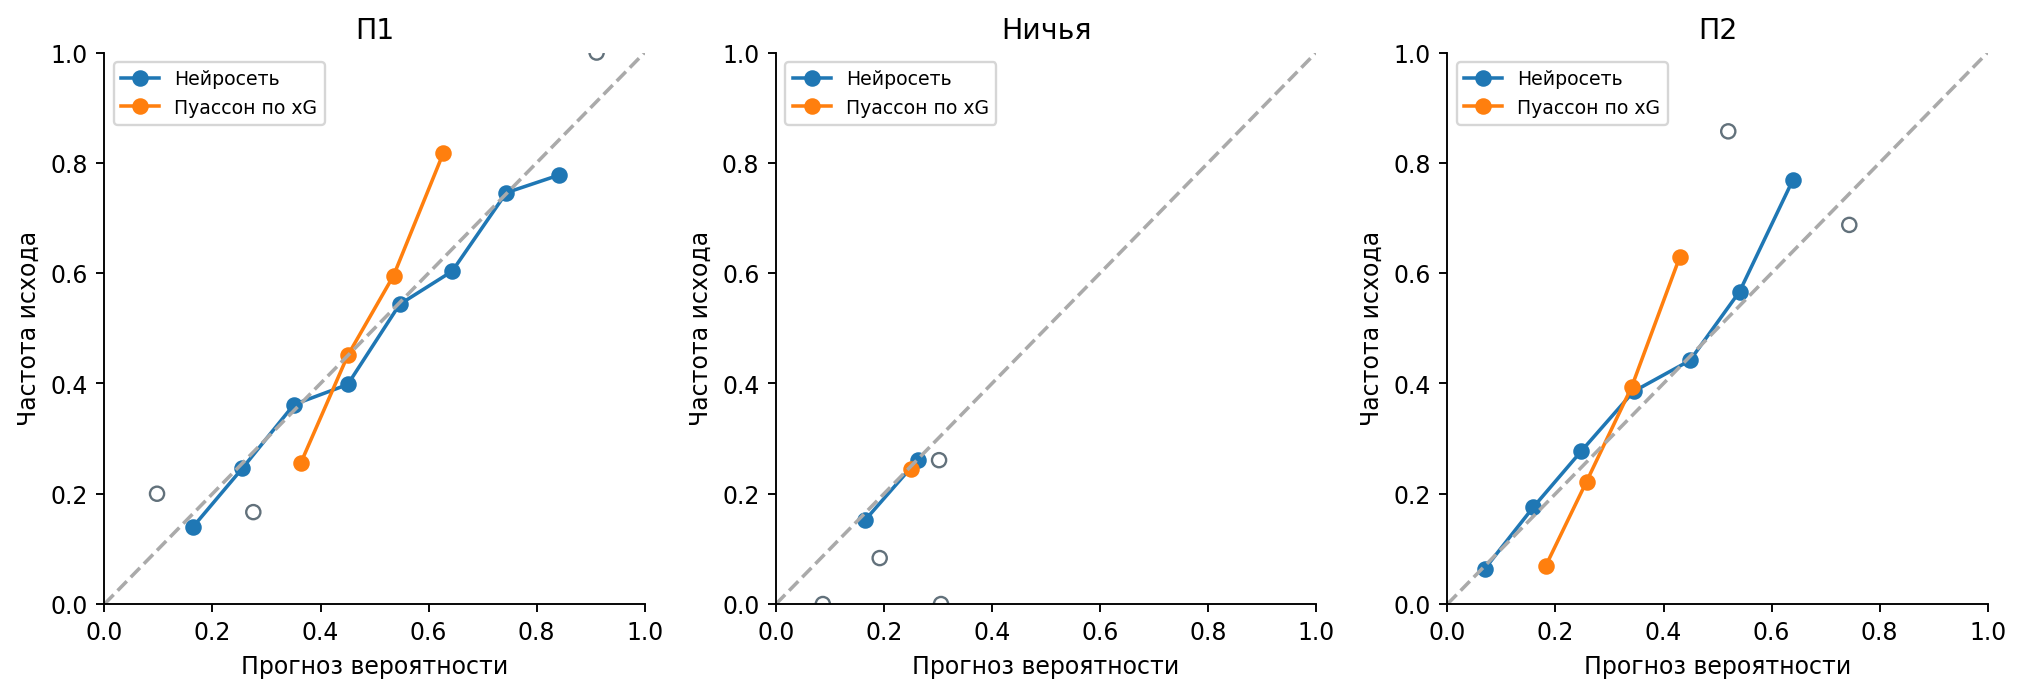

In [3]:
from match_forecast.common import scores

p = predictions[['p_neural_0', 'p_neural_1', 'p_neural_2']].to_numpy()
display(pd.Series(scores(predictions.target.to_numpy(int), p)))
display(metrics.loc[metrics.group.eq('all')])
display(Image(filename=str(FIGURES / 'final_model_quality.png'), width=1050))
display(Image(filename=str(FIGURES / 'final_probability_check.png'), width=1050))

## Ошибки и сравнение моделей

,baseline,difference,low,high,clusters
0,constant,-0.078591,-0.095332,-0.062164,41
1,elo,-0.012411,-0.020661,-0.003745,41
2,poisson,-0.033925,-0.044587,-0.023682,41


,model,group,n,log_loss,brier,accuracy
24,neural,all,1725,0.991866,0.591309,0.514203
25,neural,Bundesliga,306,0.995563,0.594386,0.506536
26,neural,EPL,380,0.978389,0.581392,0.510526
27,neural,La_Liga,380,1.008755,0.605406,0.497368
28,neural,Ligue_1,279,1.000925,0.599248,0.505376
29,neural,Serie_A,380,0.978824,0.578822,0.547368
30,neural,До перерыва,1317,1.000260,0.597457,0.509491
31,neural,После перерыва,408,0.964769,0.571462,0.529412


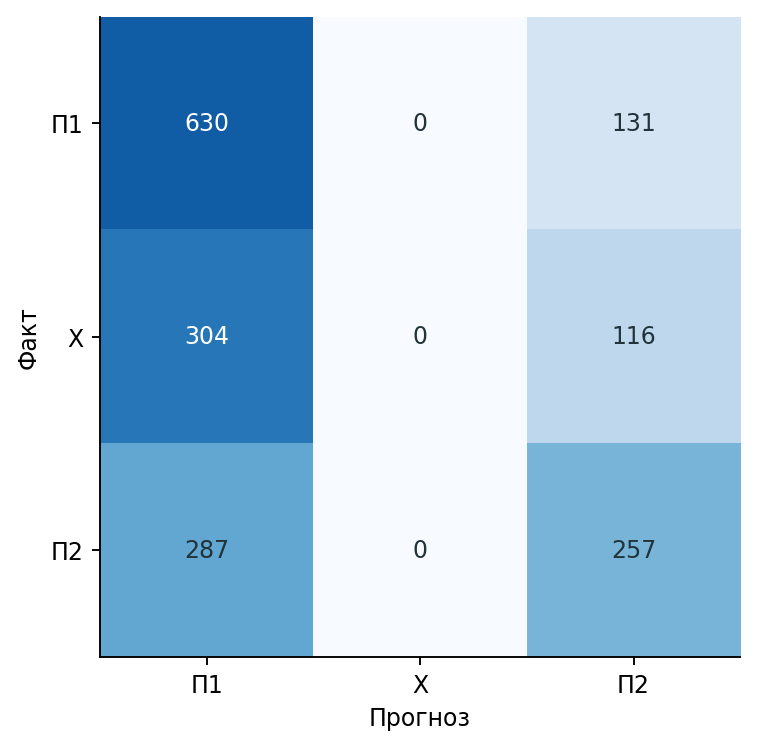

In [4]:
display(pd.read_csv(REPORTS / 'tables/final_model_comparison.csv'))
display(metrics.loc[metrics.model.eq('neural')])
display(Image(filename=str(FIGURES / 'final_confusion.png'), width=700))

## Матчи и ожидаемые очки

In [5]:
MATCH_ID = None
example = predictions.loc[predictions.match_id.eq(MATCH_ID)] if MATCH_ID else predictions.sort_values('date').tail(10)
display(example[['match_id','date','home','away','p_neural_0','p_neural_1','p_neural_2']])

,match_id,date,home,away,p_neural_0,p_neural_1,p_neural_2
1719,13467,2020-08-01,Juventus,Roma,0.621563,0.230004,0.148433
1715,13459,2020-08-01,Atalanta,Inter,0.495514,0.279659,0.224827
1716,13462,2020-08-01,Napoli,Lazio,0.534432,0.270372,0.195196
1717,13464,2020-08-01,AC Milan,Cagliari,0.752783,0.168221,0.078996
1718,13465,2020-08-01,Brescia,Sampdoria,0.360972,0.284412,0.354616
1722,13463,2020-08-02,Bologna,Torino,0.455231,0.290585,0.254185
1723,13466,2020-08-02,Genoa,Verona,0.409591,0.292221,0.298189
1720,13460,2020-08-02,SPAL 2013,Fiorentina,0.318758,0.272764,0.408478
1721,13461,2020-08-02,Sassuolo,Udinese,0.482571,0.280945,0.236484
1724,13468,2020-08-02,Lecce,Parma Calcio 1913,0.487541,0.269231,0.243228


## Очки команд

,league,teams,mae,rmse,bias,std,variance,mae_per_match
0,all,98,5.182,6.713,0.072,6.713,45.064,0.148
1,Bundesliga,18,4.561,5.517,0.301,5.509,30.345,0.134
2,EPL,20,4.996,6.426,-0.007,6.426,41.299,0.131
3,La_Liga,20,5.458,7.406,-0.432,7.393,54.662,0.144
4,Ligue_1,20,4.878,6.483,0.125,6.481,42.010,0.175
5,Serie_A,20,5.957,7.435,0.397,7.424,55.119,0.157


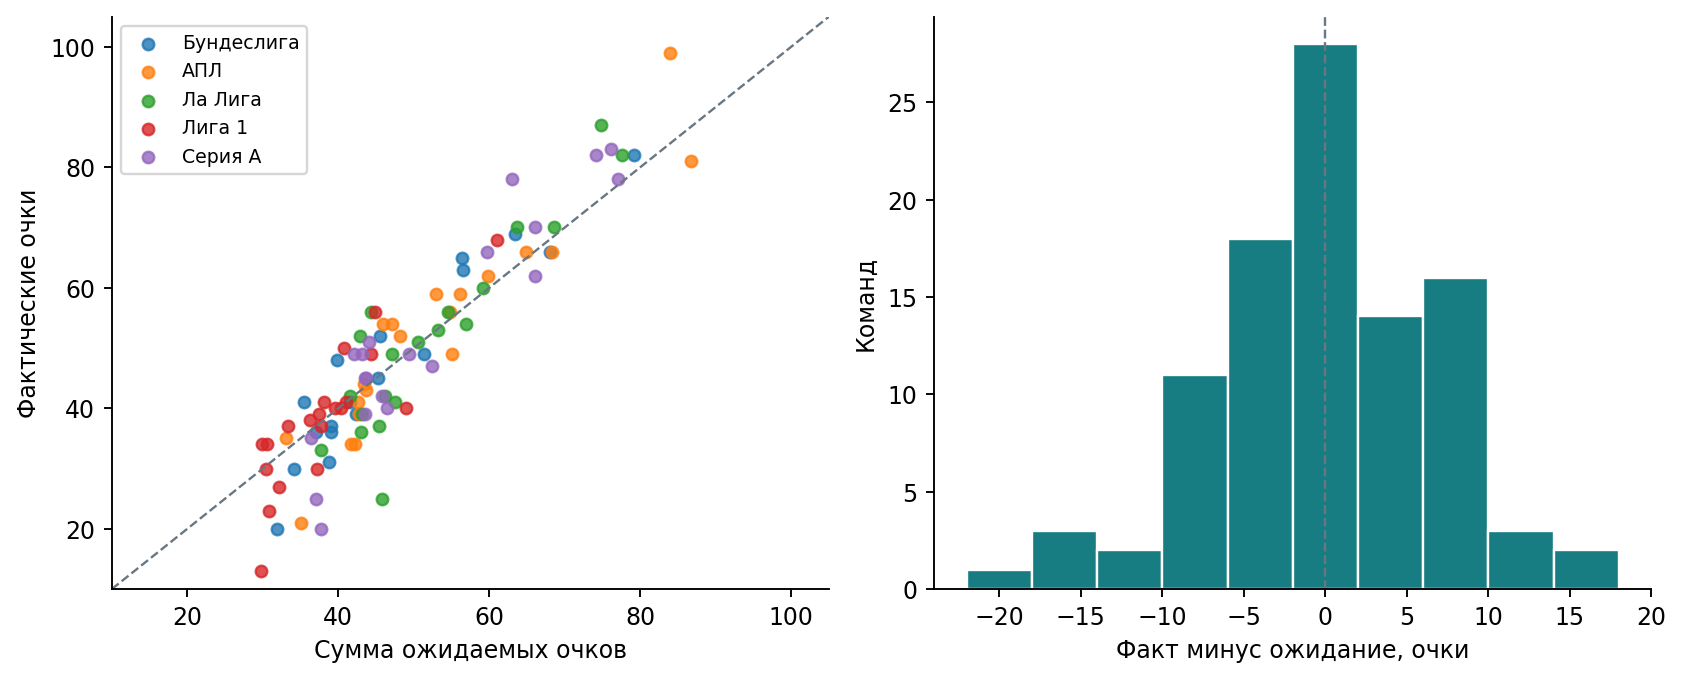

,model,mae,rmse,position_mae
0,neural,5.182,6.713,1.959
1,constant,12.227,15.813,4.980
2,elo,7.066,8.950,2.102
3,poisson,9.289,12.105,2.592


In [6]:
teams = pd.read_csv(REPORTS / 'tables/final_team_points.csv')
summary = pd.read_csv(REPORTS / 'tables/final_team_error_summary.csv')
display(summary[['league', 'teams', 'mae', 'rmse', 'bias', 'std', 'variance', 'mae_per_match']].round(3))
display(Image(filename=str(FIGURES / 'final_team_points.png'), width=1000))
display(pd.read_csv(REPORTS / 'tables/final_team_model_comparison.csv')[['model', 'mae', 'rmse', 'position_mae']].round(3))

## Места в лиге

In [7]:
display(summary[['league', 'teams', 'position_mae', 'exact_positions', 'within_2_positions', 'max_position_error']].round(2))
display(pd.read_csv(REPORTS / 'tables/final_standings_outcomes.csv'))

LEAGUE = 'EPL'
display(teams.loc[teams.league.eq(LEAGUE), ['team', 'matches', 'points', 'expected', 'difference',
                                          'actual_position', 'predicted_position', 'position_difference']].round(2))

,league,teams,position_mae,exact_positions,within_2_positions,max_position_error
0,all,98,1.96,17,68,8.0
1,Bundesliga,18,1.22,5,15,5.0
2,EPL,20,1.40,2,16,5.0
3,La_Liga,20,2.50,4,14,8.0
4,Ligue_1,20,2.10,3,11,5.0
5,Serie_A,20,2.50,3,12,7.0


,season,league,actual_winner,predicted_winner,winner_correct,top4_overlap,bottom3_overlap
0,2019,Bundesliga,Bayern Munich,Bayern Munich,True,3,2
1,2019,EPL,Liverpool,Manchester City,False,4,2
2,2019,La_Liga,Real Madrid,Barcelona,False,4,1
3,2019,Ligue_1,Paris Saint Germain,Paris Saint Germain,True,3,1
4,2019,Serie_A,Juventus,Atalanta,False,3,3


,team,matches,points,expected,difference,actual_position,predicted_position,position_difference
18,Liverpool,38,99,83.90,15.10,1,2.0,1.0
19,Manchester City,38,81,86.70,-5.70,2,1.0,-1.0
20,Manchester United,38,66,64.84,1.16,3,4.0,1.0
21,Chelsea,38,66,68.30,-2.30,4,3.0,-1.0
22,Leicester,38,62,59.87,2.13,5,5.0,0.0
23,Tottenham,38,59,52.91,6.09,6,9.0,3.0
24,Wolverhampton Wanderers,38,59,56.18,2.82,7,6.0,-1.0
25,Arsenal,38,56,54.77,1.23,8,8.0,0.0
26,Sheffield United,38,54,45.98,8.02,9,12.0,3.0
27,Burnley,38,54,47.12,6.88,10,11.0,1.0
